In [1]:
#load in 

# %%
import json
import math
from typing import Any, Dict, Iterable, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Rectangle, ConnectionPatch, Polygon

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (10, 6)

# ---- file paths: update the match_id file names accordingly ----
MATCHES_CSV   = "matches_df.csv"
LINEUPS_CSV   = "lineups_df.csv"
EVENTS_CSV    = "events_by_match/events_3795221.csv"         # change to your chosen match file #3788741 #3795506 #3795221 #3795220
FRAMES360_CSV = "frames_360_by_match/frames_360_3795221.csv"     # same match_id #3788741 #3795506 #3795221 #3795220




# %%
matches = pd.read_csv(MATCHES_CSV)
lineups = pd.read_csv(LINEUPS_CSV)
events  = pd.read_csv(EVENTS_CSV)
frames  = pd.read_csv(FRAMES360_CSV)

print("matches:", matches.shape, "| lineups:", lineups.shape, "| events:", events.shape, "| frames:", frames.shape)
print("\nEvents head columns:", list(events.columns[:20]))
print("Frames head columns:", list(frames.columns))



cols_first = [
    "type", "minute", "timestamp", "second", "location", "play_pattern", "player", "position", "shot_statsbomb_xg",
    "possession", "possession_team", "pass_angle", "pass_end_location", "pass_height", "pass_length",
    "pass_recipient", "pass_technique", "team", "period", 
]
cols_first = [c for i, c in enumerate(cols_first) if c not in cols_first[:i]]

def reorder_cols(df, cols_first):
    all_cols = df.columns.tolist()
    first = [c for c in cols_first if c in all_cols]
    rest = [c for c in all_cols if c not in first]
    return df[first + rest]

events = reorder_cols(events, cols_first)

# Convert 'timestamp' to a datetime column if not already, then sort by it
events['timestamp_dt'] = pd.to_datetime(events['timestamp'], errors='coerce')
events = events.sort_values(['possession', 'timestamp_dt'])
events = events.reset_index()

matches: (51, 22) | lineups: (2345, 10) | events: (4691, 115) | frames: (53495, 7)

Events head columns: ['fifty_fifty', 'bad_behaviour_card', 'ball_receipt_outcome', 'ball_recovery_offensive', 'ball_recovery_recovery_failure', 'block_deflection', 'block_offensive', 'block_save_block', 'carry_end_location', 'clearance_aerial_won', 'clearance_body_part', 'clearance_head', 'clearance_left_foot', 'clearance_other', 'clearance_right_foot', 'counterpress', 'dribble_no_touch', 'dribble_nutmeg', 'dribble_outcome', 'dribble_overrun']
Frames head columns: ['id', 'match_id', 'visible_area', 'teammate', 'actor', 'keeper', 'location']


/var/folders/vw/z2xv57_n70l_szw_fr80j5km0000gn/T/ipykernel_45364/2447680907.py:54: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  events['timestamp_dt'] = pd.to_datetime(events['timestamp'], errors='coerce')


In [2]:
#FUNCTIONS

#initial functions
# %%
def try_json(x):
    if pd.isna(x):
        return None
    if isinstance(x, (list, dict)):
        return x
    s = str(x)
    try:
        return json.loads(s)
    except Exception:
        # some CSVs store lists as like "[52.3, 33.2]"
        # or with single quotes — try a fallback
        try:
            return json.loads(s.replace("'", '"'))
        except Exception:
            return None

def parse_point(pt) -> Optional[Tuple[float,float]]:
    if isinstance(pt, (list, tuple)) and len(pt) >= 2:
        return float(pt[0]), float(pt[1])
    return None

def draw_pitch(ax=None, linecolor="black", lw=1):
    if ax is None:
        ax = plt.gca()
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 80)
    ax.set_aspect("equal")
    ax.axis("off")
    # outline & halves
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=linecolor, lw=lw))
    ax.plot([60, 60], [0, 80], color=linecolor, lw=lw)
    # boxes
    ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, ec=linecolor, lw=lw))      # left box (18-yard)
    ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, ec=linecolor, lw=lw))     # right box (18-yard)
    # six-yard boxes
    ax.add_patch(Rectangle((0, 30), 6, 20, fill=False, ec=linecolor, lw=lw))        # left 6-yard box
    ax.add_patch(Rectangle((114, 30), 6, 20, fill=False, ec=linecolor, lw=lw))      # right 6-yard box

    # goal frames
    # Left goal frame (placed at x=0, center at y=40, width ~0.5, height 8 yards: y=36 to 44)
    ax.add_patch(Rectangle((-0.5, 36), 0.5, 8, fill=False, ec=linecolor, lw=lw*2))
    # Right goal frame (placed at x=120, center at y=40)
    ax.add_patch(Rectangle((120, 36), 0.5, 8, fill=False, ec=linecolor, lw=lw*2))

    # penalty spots & arcs
    ax.plot(12, 40, 'o', color=linecolor, ms=2)
    ax.plot(108, 40, 'o', color=linecolor, ms=2)
    ax.add_patch(Arc((12, 40), 20, 20, angle=0, theta1=-90, theta2=90, ec=linecolor, lw=lw))
    ax.add_patch(Arc((108, 40), 20, 20, angle=0, theta1=90, theta2=270, ec=linecolor, lw=lw))
    # center circle
    ax.add_patch(Arc((60, 40), 20, 20, angle=0, theta1=0, theta2=360, ec=linecolor, lw=lw))
    return ax


def try_json(x):
    if pd.isna(x):
        return None
    if isinstance(x, (list, dict)):
        return x
    s = str(x)
    try:    
        return json.loads(s)
    except Exception:
        return None

def parse_point(pt) -> Optional[Tuple[float,float]]:
    if isinstance(pt, (list, tuple)) and len(pt) >= 2:
        return float(pt[0]), float(pt[1])


from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import matplotlib.image as mpimg

def add_soccer_ball(ax, x, y, size=0.05):
    ball_img = mpimg.imread("soccer_ball.png")  # path to your ball icon
    imagebox = OffsetImage(ball_img, zoom=size)
    ab = AnnotationBbox(imagebox, (x, y), frameon=False)
    ax.add_artist(ab)

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import matplotlib.image as mpimg

def plot_three_sixty(df, ball_icon_path="soccer_ball.png", ball_zoom=0.05):
    """
    Plots player locations from a three-sixty dataframe with columns:
    id, match_id, visible_area, teammate, actor, keeper, location.
    Teammates: blue, Keepers: red, Others: gray.
    If 'actor' == 1, mark with ring and draw a soccer ball next to their dot.

    Parameters
    ----------
    df : pandas.DataFrame
        Three-sixty dataframe with 'location', 'teammate', 'keeper', and 'actor' columns.
    ball_icon_path : str
        Path to soccer ball PNG.
    ball_zoom : float
        Scaling factor for soccer ball size (default 0.05).
    """

    # --- Helper: Draw pitch ---
    def draw_pitch(ax, pitch_length=120, pitch_width=80):
        # Outline & Centre Line
        ax.plot([0, 0], [0, pitch_width], color="black")
        ax.plot([0, pitch_length], [pitch_width, pitch_width], color="black")
        ax.plot([pitch_length, pitch_length], [pitch_width, 0], color="black")
        ax.plot([pitch_length, 0], [0, 0], color="black")
        ax.plot([pitch_length/2, pitch_length/2], [0, pitch_width], color="black")

        # Penalty areas
        ax.plot([102, 102], [18, pitch_width-18], color="black")  # Right PA
        ax.plot([pitch_length, 102], [18, 18], color="black")
        ax.plot([pitch_length, 102], [pitch_width-18, pitch_width-18], color="black")
        ax.plot([18, 18], [18, pitch_width-18], color="black")
        ax.plot([0, 18], [18, 18], color="black")
        ax.plot([0, 18], [pitch_width-18, pitch_width-18], color="black")

        # Centre circle
        centreCircle = plt.Circle((pitch_length/2, pitch_width/2), 10, color="black", fill=False)
        ax.add_patch(centreCircle)

        # Add goal frame on the left (x=0), center at y=40, about 8 yards tall
        # The goal posts run from y=36 to y=44 (8 yards high, at midfield in y)
        from matplotlib.patches import Rectangle, Circle
        ax.add_patch(Rectangle((-0.5, 36), 0.5, 8, fill=False, ec="black", lw=2))  # left goal frame

        # Add goal frame on the right (x=120), center at y=40, about 8 yards tall
        ax.add_patch(Rectangle((pitch_length, 36), 0.5, 8, fill=False, ec="black", lw=2))  # right goal frame

        # Add 6-yard box on left
        ax.add_patch(Rectangle((0, (pitch_width/2)-10), 6, 20, fill=False, ec="black", lw=1))  # left 6-yard box

        # Add 6-yard box on right
        ax.add_patch(Rectangle((pitch_length-6, (pitch_width/2)-10), 6, 20, fill=False, ec="black", lw=1))  # right 6-yard box

        # Add penalty spot on left (12 yards from goal line, center)
        ax.add_patch(Circle((12, pitch_width/2), 0.7, color='black'))

        # Add penalty spot on right (pitch_length - 12, center)
        ax.add_patch(Circle((pitch_length-12, pitch_width/2), 0.7, color='black'))

        ax.set_xlim(0, pitch_length)
        ax.set_ylim(0, pitch_width)
        ax.axis('off')

    # --- Helper: Parse location ---
    def parse_location(loc):
        if isinstance(loc, (list, tuple)) and len(loc) >= 2:
            return float(loc[0]), float(loc[1])
        if isinstance(loc, str):
            try:
                import ast
                pt = ast.literal_eval(loc)
                if isinstance(pt, (list, tuple)) and len(pt) >= 2:
                    return float(pt[0]), float(pt[1])
            except Exception:
                pass
        return None

    # --- Helper: Add soccer ball icon ---
    def add_soccer_ball(ax, x, y, icon_path=ball_icon_path, zoom=ball_zoom):
        try:
            img = mpimg.imread(icon_path)
            imagebox = OffsetImage(img, zoom=zoom)
            ab = AnnotationBbox(imagebox, (x, y), frameon=False, zorder=8)
            ax.add_artist(ab)
        except FileNotFoundError:
            print(f"⚠️ Soccer ball image not found at '{icon_path}'. Skipping icon.")

    # --- Collect player coordinates ---
    x, y, colors = [], [], []
    actors_x, actors_y, actors_color = [], [], []

    for _, r in df.iterrows():
        pt = parse_location(r["location"])
        if pt is None:
            continue
        if r.get("teammate", 0) == 1:
            c = "blue"
        elif r.get("keeper", 0) == 1:
            c = "red"
        else:
            c = "gray"

        if r.get("actor", 0) == 1:
            actors_x.append(pt[0])
            actors_y.append(pt[1])
            actors_color.append(c)
        else:
            x.append(pt[0])
            y.append(pt[1])
            colors.append(c)

    # --- Plot setup ---
    fig, ax = plt.subplots(figsize=(10, 7))
    draw_pitch(ax)

    # Plot all players
    ax.scatter(x, y, c=colors, s=100, edgecolors='black', zorder=3)

    # Plot actors + soccer ball
    for px, py, c in zip(actors_x, actors_y, actors_color):
        ax.scatter([px], [py], c=c, s=100, edgecolors='black', zorder=5)
        ring = plt.Circle((px, py), 7, color="gold", fill=False, linewidth=2.5, zorder=6)
        ax.add_patch(ring)
        add_soccer_ball(ax, px+3, py)  # small offset to the right

    plt.show()

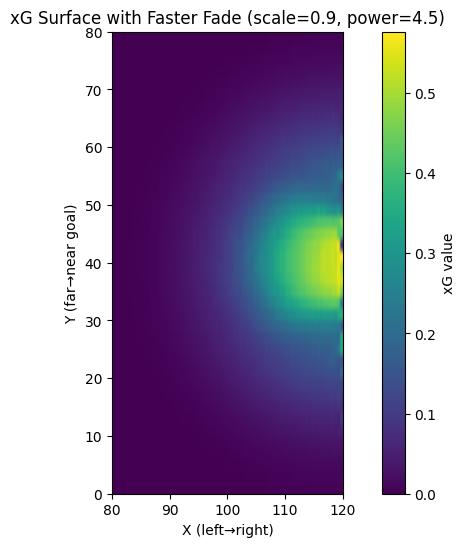

Heatmap value at X=100, Y=30 is 0.083


In [3]:
#aside - finding xG maps
from PIL import Image
import numpy as np

# Load the original map
img = Image.open("1_bFvE_1i24RrLITBIcA-QKQ.jpg").convert("RGB")
arr = np.array(img) / 255.0

# Convert to HSV
import colorsys
hsv = np.zeros_like(arr)
for i in range(arr.shape[0]):
    for j in range(arr.shape[1]):
        hsv[i, j] = colorsys.rgb_to_hsv(*arr[i, j])

# Hue channel encodes the color progression (cyan→green→yellow→orange)
hue = hsv[..., 0]

# Invert hue so that yellow/orange (high xG) → high values
# and cyan/blue (low xG) → low values
xg_grid = 1 - hue

# Normalize to [0, 0.6]
xg_grid = (xg_grid - xg_grid.min()) / (xg_grid.max() - xg_grid.min()) * 0.6

# Flip X and Y: swap axes 0 and 1
xg_grid_flipped = np.transpose(xg_grid)
xg_grid_flipped = xg_grid_flipped[:, ::-1]  # Flip columns, not rows


# Utility function to map from field units to array indices
def x_to_col(x):
    return int(round((x - 80) / (40 / (xg_grid_flipped.shape[1] - 1))))

def y_to_row(y):
    return int(round(y / (80 / (xg_grid_flipped.shape[0] - 1))))

# Set up indices for your new regions
x_start, x_end = x_to_col(80), x_to_col(90)

y_source_start, y_source_end = y_to_row(57), y_to_row(80)
y_target_start, y_target_end = y_to_row(0), y_to_row(23)
region_height = y_source_end - y_source_start
if (y_target_end - y_target_start) != region_height:
    y_target_end = y_target_start + region_height

# Copy, flip, paste
region = xg_grid_flipped[y_source_start:y_source_end, x_start:x_end]
region_flipped = region[::-1, :]
xg_grid_flipped[y_target_start:y_target_end, x_start:x_end] = region_flipped


import numpy as np
from scipy.interpolate import RegularGridInterpolator

# Original grid coordinates (based on array shape)
y_old = np.linspace(0, 80, xg_grid_flipped.shape[0])   # 646 points
x_old = np.linspace(80, 120, xg_grid_flipped.shape[1])  # 281 points

# Build interpolator over your dense grid
interp = RegularGridInterpolator((y_old, x_old), xg_grid_flipped)

# New grid coordinates (exactly what you want on the field)
y_new = np.linspace(0, 80, 40)   # 40 evenly spaced Y values
x_new = np.linspace(80, 120, 80) # 80 evenly spaced X values

# Create meshgrid of those coordinates
yy, xx = np.meshgrid(y_new, x_new, indexing='ij')

# Interpolate
xg_grid_40x80 = interp(np.column_stack([yy.ravel(), xx.ravel()])).reshape(40, 80)
mask = (yy < 10) | (yy > 70) | (xx < 82)
xg_grid_40x80[mask] = 0.302



import numpy as np
import matplotlib.pyplot as plt

# assuming xg_grid_40x80, y_vals, x_vals from before
y_vals = np.linspace(0, 80, xg_grid_40x80.shape[0])
x_vals = np.linspace(80, 120, xg_grid_40x80.shape[1])
yy, xx = np.meshgrid(y_vals, x_vals, indexing='ij')

# Center of bright region
center_x, center_y = 120, 40

# Stretch factors (ellipticity)
X_STRETCH = 2.0
Y_STRETCH = 1.75

# Compute "elliptical" distance
dist = np.sqrt(((xx - center_x) * X_STRETCH)**2 + ((yy - center_y) * Y_STRETCH)**2)

# Diagonal length (max distance)
max_dist = np.sqrt(((120 - 80) * X_STRETCH)**2 + ((80 - 40) * Y_STRETCH)**2)

# Fade control
FADE_SCALE = 0.9   # <1 fades faster overall
FADE_POWER = 4.5   # >3 fades harder near edges

# Compute fade mask
fade_cos = np.clip(np.cos(0.5 * np.pi * dist / (max_dist * FADE_SCALE)), 0, 1)
fade_mask = fade_cos ** FADE_POWER

# Apply fade
xg_grid_faded = xg_grid_40x80 * fade_mask

# Renormalize
if np.max(xg_grid_faded) > 0:
    xg_grid_faded *= xg_grid_40x80.max() / np.max(xg_grid_faded)

# Plot
plt.imshow(xg_grid_faded, origin='upper', extent=[80, 120, 0, 80])
plt.xlabel("X (left→right)")
plt.ylabel("Y (far→near goal)")
plt.title(f"xG Surface with Faster Fade (scale={FADE_SCALE}, power={FADE_POWER})")
plt.colorbar(label="xG value")
plt.show()


import numpy as np

# The grid you want to sample
grid = xg_grid_faded

def x_to_col(x, shape=grid.shape):
    """
    Maps an X field coordinate (80→120) to the grid column index (0→n_cols-1)
    """
    x = np.clip(x, 80, 120)
    n_cols = shape[1]
    # linear map from [80,120] → [0, n_cols-1]
    col = int(round((x - 80) / (120 - 80) * (n_cols - 1)))
    return col

def y_to_row(y, shape=grid.shape):
    """
    Maps a Y field coordinate (0→80) to the grid row index (0→n_rows-1)
    """
    y = np.clip(y, 0, 80)
    n_rows = shape[0]
    # linear map from [0,80] → [0, n_rows-1]
    row = int(round(y / 80 * (n_rows - 1)))
    return row

def get_heatmap_value(x, y, grid=grid):
    """
    Returns interpolated (nearest-cell) heatmap value for a given (x,y)
    """
    row = y_to_row(y, grid.shape)
    col = x_to_col(x, grid.shape)
    return grid[row, col]

# 🔍 Example usage:
x_val, y_val = 100, 30
value = get_heatmap_value(x_val, y_val)
print(f"Heatmap value at X={x_val}, Y={y_val} is {value:.3f}")



In [4]:
#Isolate shots 
# %%
shots = events[events["type"] == "Shot"].copy()
shots["xy"] = shots["location"].apply(try_json).apply(parse_point)
shots["end_xy"] = shots["shot_end_location"].apply(try_json).apply(parse_point) if "shot_end_location" in shots.columns else None

shots["x"] = shots["xy"].apply(lambda p: p[0] if p else np.nan)
shots["y"] = shots["xy"].apply(lambda p: p[1] if p else np.nan)
if "shot_statsbomb_xg" in shots.columns:
    shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
else:
    shots["xg"] = np.nan

In [5]:
pass_cross = events[events['pass_cross'] == 1]
pass_cross_event_ids = pass_cross['id'].unique()

In [6]:

# Convert location from string like "[70.9, 9.3]" into numeric x, y
def parse_location(loc):
    # If already a list, return
    if isinstance(loc, list):
        return loc
    # If string, try to parse as JSON-like list
    if isinstance(loc, str):
        try:
            return json.loads(loc)
        except Exception:
            # Try stripping and splitting if not valid JSON
            s = loc.strip("[]").split(",")
            if len(s) == 2:
                try:
                    return [float(s[0]), float(s[1])]
                except Exception:
                    return [np.nan, np.nan]
    return [np.nan, np.nan]

events["parsed_location"] = events["location"].apply(parse_location)
events["x"] = events["parsed_location"].apply(lambda loc: loc[0] if loc and isinstance(loc, list) else np.nan)
events["y"] = events["parsed_location"].apply(lambda loc: loc[1] if loc and isinstance(loc, list) else np.nan)


In [7]:
#plotting cross effectiveness heatmap - attempt #1
for id_unique in pass_cross_event_ids[0:32]:
    this_three_sixty = frames[frames['id'] == id_unique]

    # Find the row in eventas with this id
    event_row = events[events['id'] == id_unique]

    # Get the timestamp of the event
    event_timestamp = pd.to_datetime(event_row['timestamp'].iloc[0])

    # Filter for all rows in events with timestamp within 5 seconds BEFORE the event
    mask_prior_5_sec = (events['timestamp_dt'] >= (event_timestamp - pd.Timedelta(seconds=10))) & \
                       (events['timestamp_dt'] <= event_timestamp)
    events_prior_5s = events[mask_prior_5_sec]
    events_prior_5s = events_prior_5s[
        (events_prior_5s['minute'] == event_row['minute'].iloc[0]) |
        (events_prior_5s['minute'] == event_row['minute'].iloc[0] - 1)
    ]

    end_location = event_row['pass_end_location']
    start_location = event_row['location']
    end_outcome = event_row['pass_outcome']

    events_prior_5s["time_diff"] = events_prior_5s["timestamp_dt"].diff().dt.total_seconds()
    events_prior_5s["dx"] = events_prior_5s["x"].diff()
    events_prior_5s["dy"] = events_prior_5s["y"].diff()
    events_prior_5s["dist"] = np.sqrt(events_prior_5s["dx"]**2 + events_prior_5s["dy"]**2)
    events_prior_5s["speed_m_s"] = events_prior_5s["dist"] / events_prior_5s["time_diff"]
    events_prior_5s["forward_speed_m_s"] = events_prior_5s["dx"] / events_prior_5s["time_diff"]  # horizontal pitch direction

    ids_in_window = events_prior_5s["id"].unique()
    frames_subset = frames[frames["id"].isin(ids_in_window)].copy()

    # attach timestamps of each event
    frames_subset = frames_subset.merge(
        events_prior_5s[["id", "timestamp_dt"]],
        on="id",
        how="left",
        suffixes=("", "_event")
    )

    frames_subset["x"], frames_subset["y"] = zip(*frames_subset["location"].apply(lambda v: parse_point(try_json(v))))

    frame_summary = (
        frames_subset.groupby(["id", "timestamp_dt"], as_index=False)
        .agg(mean_x=("x", "mean"),
             mean_y=("y", "mean"))
        .sort_values("timestamp_dt")
    )

    frame_summary["dx"] = frame_summary["mean_x"].diff()
    frame_summary["dt"] = frame_summary["timestamp_dt"].diff().dt.total_seconds()
    
    # Avoid division by zero and suppress RuntimeWarnings
    frame_summary["vx_m_s"] = np.where(
        frame_summary["dt"] == 0,
        np.nan,
        frame_summary["dx"] / frame_summary["dt"]
    )

    total_dx = frame_summary["dx"].sum()
    total_dt = frame_summary["dt"].sum()
    if total_dt == 0 or np.isnan(total_dt):
        net_vx_m_s = np.nan
    else:
        net_vx_m_s = total_dx / total_dt

    mean_abs_vx_m_s = frame_summary["vx_m_s"].abs().mean()

    vx_summary = {
        "total_dx": total_dx,
        "total_dt": total_dt,
        "net_vx_m_s": net_vx_m_s,
        "mean_abs_vx_m_s": mean_abs_vx_m_s,
    }

    dx_sum = total_dx
    dt_sum = total_dt
    # net_vx_m_s variable already set in safe way above
    # mean_abs_vx_m_s variable already set above


In [8]:
"""
Given:

- The speed of play (4 variables): dx_sum, dt_sum, net_vx_m_s, mean_abs_vx_m_s
- The start location of the ball (start_location)
- The locations of teammates in the frame at the time of the cross (from this_three_sixty, every row where teammate == 1; location as [X, Y])
- The location of the goalkeeper at the time of the cross (from this_three_sixty, every row where keeper == 1; location as [X, Y])
- The locations of defenders at the time of the cross (from this_three_sixty, every row where teammate == 0; location as [X, Y])

Goal:

To generate a plot of the penalty area showing the most effective delivery zones for the crosser, represented as a heatmap. "Hot" areas indicate better delivery options given the speed of play, ball start location, and player locations. This heatmap visualizes a data structure where, for each location, the value corresponds to the expected goals (xG) if a shot were to occur from that location.
"""

'\nGiven:\n\n- The speed of play (4 variables): dx_sum, dt_sum, net_vx_m_s, mean_abs_vx_m_s\n- The start location of the ball (start_location)\n- The locations of teammates in the frame at the time of the cross (from this_three_sixty, every row where teammate == 1; location as [X, Y])\n- The location of the goalkeeper at the time of the cross (from this_three_sixty, every row where keeper == 1; location as [X, Y])\n- The locations of defenders at the time of the cross (from this_three_sixty, every row where teammate == 0; location as [X, Y])\n\nGoal:\n\nTo generate a plot of the penalty area showing the most effective delivery zones for the crosser, represented as a heatmap. "Hot" areas indicate better delivery options given the speed of play, ball start location, and player locations. This heatmap visualizes a data structure where, for each location, the value corresponds to the expected goals (xG) if a shot were to occur from that location.\n'

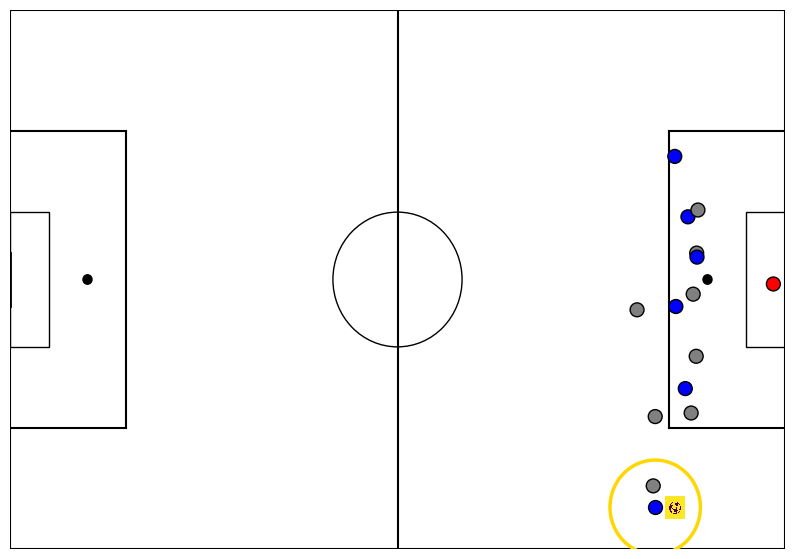

In [9]:
# Example usage:
plot_three_sixty(this_three_sixty, ball_icon_path="soccer_ball.png", ball_zoom=0.0055)


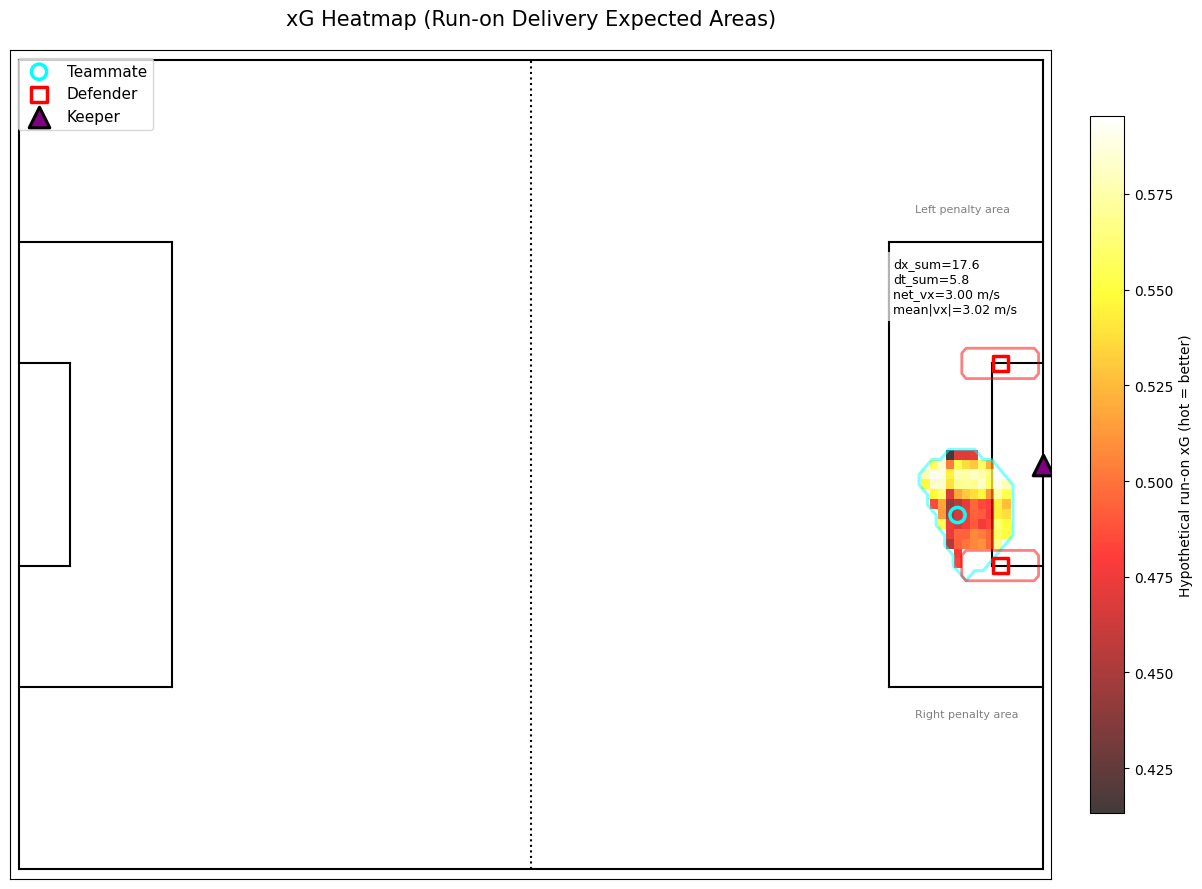

(array([[       nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan],
        [       nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan],
        [       nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan],
        [       nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan

In [ ]:
#cross effectiveness heatmap - attempt #1
import matplotlib.pyplot as plt
import numpy as np

# You might need to check here if this_three_sixty is fresh and columns exist, but assuming the old code structure:

teammates_df = this_three_sixty[this_three_sixty['teammate'] == 1]
defenders_df = this_three_sixty[this_three_sixty['teammate'] == 0]
keeper_df = this_three_sixty[this_three_sixty['keeper'] == 1]

teammates_locations = extract_locations_safe(teammates_df, 'location')
defenders_locations = extract_locations_safe(defenders_df, 'location')
keeper_location = None
if not keeper_df.empty:
    v = keeper_df.iloc[0]['location']
    if isinstance(v, (list, np.ndarray)) and len(v) == 2:
        keeper_location = [float(v[0]), float(v[1])]

# Safeguard: If literally no teammates or defenders/keeper, fallback to example dummy points to visualize!
if not teammates_locations:
    teammates_locations = [[110, 35]]
if not defenders_locations:
    defenders_locations = [[115, 30], [115, 50]]
if keeper_location is None:
    keeper_location = [120, 40]

# Overlay markers will now always show up visually:
player_location = start_location  # or you can use another variable if you have a separate one

generate_penalty_area_heatmap_on_pitch_expected_runons(
    xg_from_xy,
    start_location,
    teammates_locations,
    keeper_location,
    defenders_locations,
    dx_sum,
    dt_sum,
    net_vx_m_s,
    mean_abs_vx_m_s,
    player_location=player_location  # <-- overlay player location!
)


In [21]:
this_three_sixty

,id,match_id,visible_area,teammate,actor,keeper,location
50719,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",0,0,0,"[97.093499031061, 35.50053630411805]"
50720,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",0,0,0,"[99.5962240829194, 9.366111932739415]"
50721,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",1,1,0,"[99.9000015258789, 6.199999809265137]"
50722,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",0,0,0,"[99.90360227855787, 19.653612820966067]"
50723,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",1,0,0,"[102.93441879632962, 58.269579564848996]"
50724,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",1,0,0,"[103.10205215861511, 35.99281695485765]"
50725,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",1,0,0,"[104.56092868935232, 23.808305455364604]"
50726,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",1,0,0,"[104.9699396789863, 49.303056258586]"
50727,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",0,0,0,"[105.46879226606825, 20.18444929771684]"
50728,d2bc3fd6-115b-49ba-92aa-a588e84bea19,3795221,"[109.557063784562, 80.0, 80.54760864919, 5.226...",0,0,0,"[105.78443483613506, 37.82524830775108]"


In [ ]:
start_location = start_location.iloc[0]
# Overlay markers will now always show up visually:
player_location = eval(start_location)  # or you can use another variable if you have a separate one

<Figure size 1000x600 with 0 Axes>

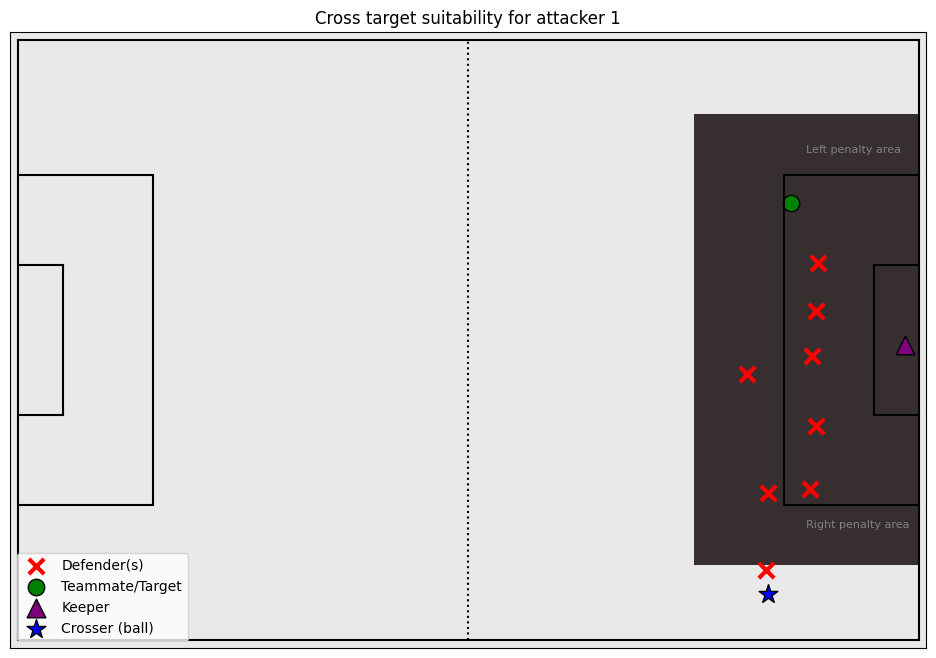

<Figure size 1000x600 with 0 Axes>

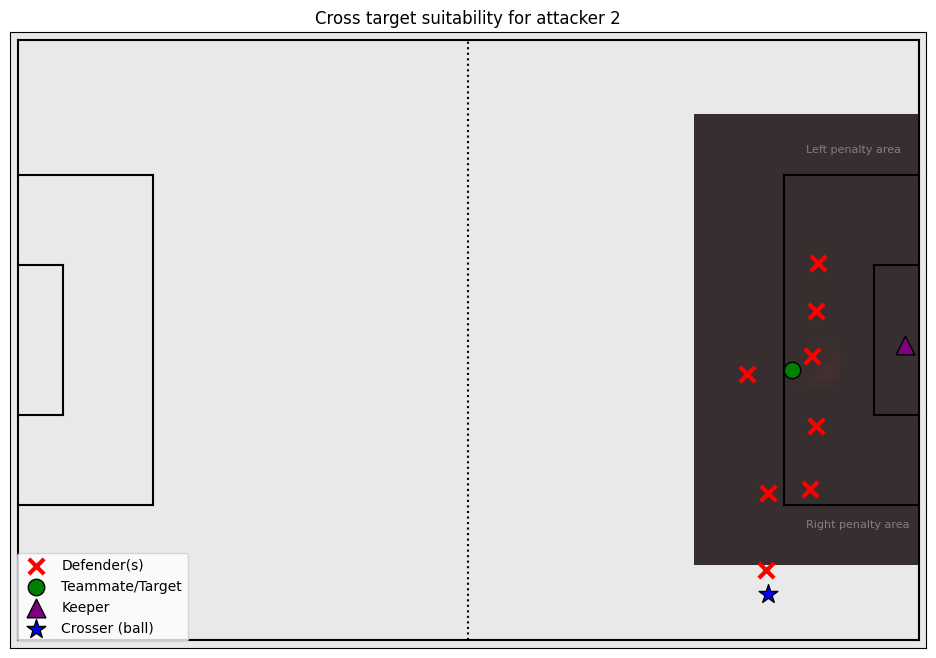

<Figure size 1000x600 with 0 Axes>

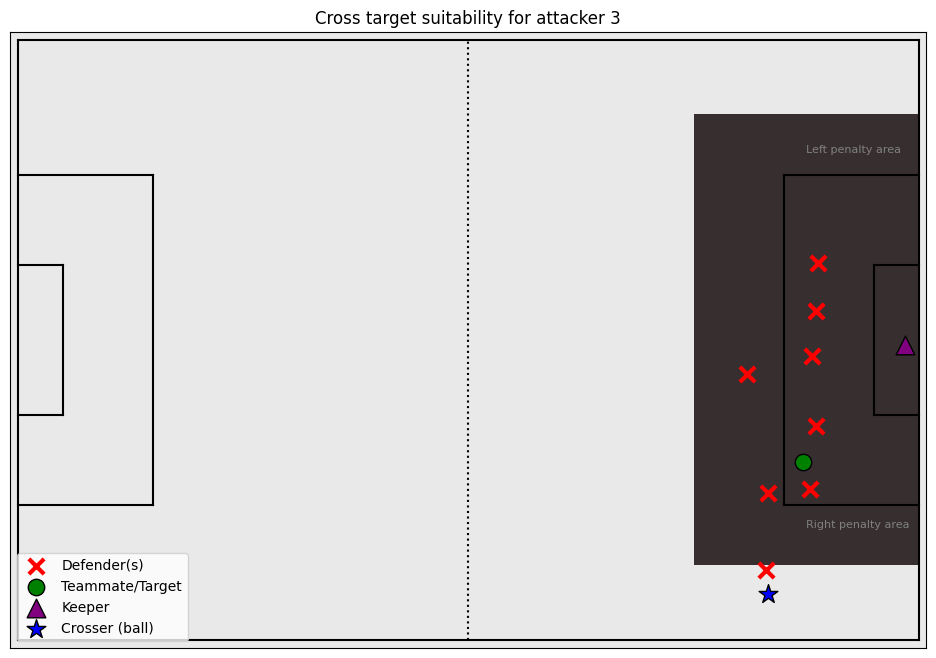

<Figure size 1000x600 with 0 Axes>

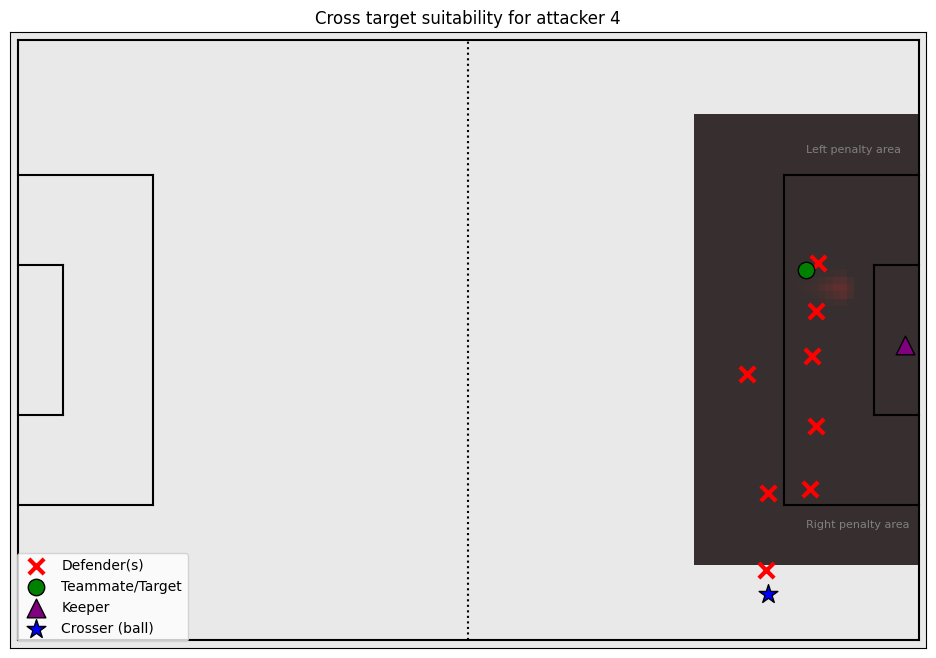

<Figure size 1000x600 with 0 Axes>

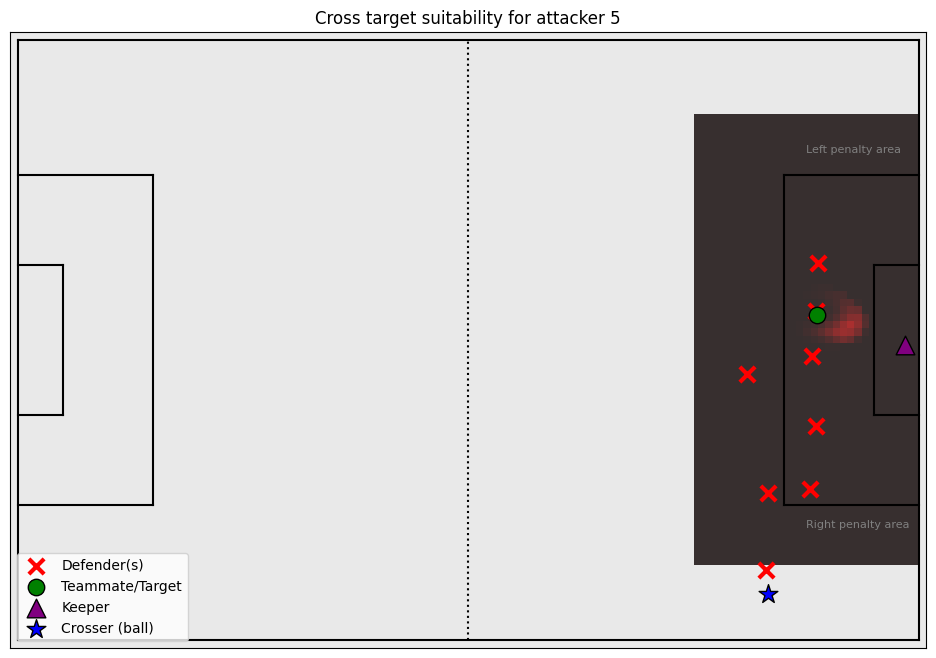

In [34]:
#plotting cross effectiveness heatmap - attempt #2
import ast
import numpy as np

# === Create xg_from_xy using your existing grid accessors ===
def xg_from_xy(x, y):
    """Return xG value at (x, y) from xg_grid_faded."""
    # Make sure global grid is available
    global xg_grid_faded
    return get_heatmap_value(x, y, grid=xg_grid_faded)


def draw_pitch(ax=None, pitch_color="#e9e9e9", line_color="black", annotate_boxes=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
        ax.set_facecolor(pitch_color)
    ax.plot([0, 0], [0, 80], color=line_color)
    ax.plot([0, 120], [80, 80], color=line_color)
    ax.plot([120, 120], [80, 0], color=line_color)
    ax.plot([120, 0], [0, 0], color=line_color)
    ax.plot([60, 60], [0, 80], color=line_color, linestyle=':')
    ax.plot([18, 18], [18, 62], color=line_color)
    ax.plot([0, 18], [62, 62], color=line_color)
    ax.plot([18, 0], [18, 18], color=line_color)
    ax.plot([102, 102], [18, 62], color=line_color)
    ax.plot([102, 120], [62, 62], color=line_color)
    ax.plot([120, 102], [18, 18], color=line_color)
    ax.plot([0, 6], [30, 30], color=line_color)
    ax.plot([6, 6], [30, 50], color=line_color)
    ax.plot([6, 0], [50, 50], color=line_color)
    ax.plot([120, 114], [30, 30], color=line_color)
    ax.plot([114, 114], [30, 50], color=line_color)
    ax.plot([114, 120], [50, 50], color=line_color)
    ax.set_xlim(-1, 121)
    ax.set_ylim(-1, 81)
    ax.set_xticks([])
    ax.set_yticks([])
    if annotate_boxes:
        ax.text(105, 65, "Left penalty area", fontsize=8, color="gray")
        ax.text(105, 15, "Right penalty area", fontsize=8, color="gray")
    ax.set_aspect('equal')
    return ax

def simulate_teammate_reach(teammate_pos, dx_sum, dt_sum, net_vx_m_s, pitch_x_min, pitch_x_max, pitch_y_min, pitch_y_max):
    run_time = max(min(dt_sum, 1.7), 1.1)
    base_run_vel = max(net_vx_m_s, 4.0)
    max_run_dist = min(base_run_vel * run_time, max(3.0, dx_sum + 6.0), 21.0)
    ellipse_a = max_run_dist
    ellipse_b = max(6.0, 0.6 * max_run_dist)
    cx, cy = teammate_pos
    goal_cx, goal_cy = 120, 40
    theta = np.arctan2(goal_cy - cy, goal_cx - cx)
    xpts = np.arange(pitch_x_min, pitch_x_max + 1.0, 1.0)
    ypts = np.arange(pitch_y_min, pitch_y_max + 1.0, 1.0)
    xx, yy = np.meshgrid(xpts, ypts)
    dx = xx - cx
    dy = yy - cy
    dx_rot = np.cos(-theta) * dx - np.sin(-theta) * dy
    dy_rot = np.sin(-theta) * dx + np.cos(-theta) * dy
    mask = ((dx_rot >= -2.5) & ((dx_rot/ellipse_a)**2 + (dy_rot/ellipse_b)**2 <= 1.05))
    return mask

def simulate_defender_blocks(defender_pos, dx_sum, dt_sum, net_vx_m_s, pitch_x_min, pitch_x_max, pitch_y_min, pitch_y_max):
    block_time = max(min(dt_sum, 1.3), 0.5)
    defend_speed = max(3.7, net_vx_m_s*0.77)
    max_def_dist = min(defend_speed * block_time, 7.0)
    a = max(2.2, max_def_dist)
    b = max(1.8, 0.4 * max_def_dist)
    cx, cy = defender_pos
    xpts = np.arange(pitch_x_min, pitch_x_max + 1.0, 1.0)
    ypts = np.arange(pitch_y_min, pitch_y_max + 1.0, 1.0)
    xx, yy = np.meshgrid(xpts, ypts)
    dx = xx - cx
    dy = yy - cy
    mask = ((dx/a)**2 + (dy/b)**2 <= 1.06)
    return mask

def generate_penalty_area_heatmap_on_pitch_expected_runons(
    xg_from_xy,
    start_location,
    teammates_locations,
    keeper_location,
    defenders_locations,
    dx_sum,
    dt_sum,
    net_vx_m_s,
    mean_abs_vx_m_s,
    player_location=None,
    grid_resolution=1.0
):
    # Define pitch and penalty area bounds explicitly
    pitch_x_min = 0
    pitch_x_max = 120
    pitch_y_min = 0
    pitch_y_max = 80
    penalty_x_min = 102
    penalty_x_max = 120
    penalty_y_min = 18
    penalty_y_max = 62

    x_grid = np.arange(penalty_x_min, penalty_x_max + grid_resolution, grid_resolution)
    y_grid = np.arange(penalty_y_min, penalty_y_max + grid_resolution, grid_resolution)
    xx, yy = np.meshgrid(x_grid, y_grid)
    out_shape = xx.shape

    teammates_locs = np.array(teammates_locations)
    defenders_locs = np.array(defenders_locations)
    valid_teammate_masks = []
    if len(teammates_locs) > 0 and teammates_locs.shape[1] == 2:
        for thismate in teammates_locs:
            mask = simulate_teammate_reach(thismate, dx_sum, dt_sum, net_vx_m_s, penalty_x_min, penalty_x_max, penalty_y_min, penalty_y_max)
            valid_teammate_masks.append(mask)
    block_masks = []
    if len(defenders_locs) > 0 and defenders_locs.shape[1] == 2:
        for thisdef in defenders_locs:
            mask = simulate_defender_blocks(thisdef, dx_sum, dt_sum, net_vx_m_s, penalty_x_min, penalty_x_max, penalty_y_min, penalty_y_max)
            block_masks.append(mask)
    if not valid_teammate_masks:
        teammate_zone = np.ones(out_shape, dtype=bool)
    else:
        teammate_zone = np.logical_or.reduce(valid_teammate_masks)
    if not block_masks:
        covered_by_defenders = np.zeros(out_shape, dtype=bool)
    else:
        covered_by_defenders = np.logical_or.reduce(block_masks)
    show_all = not valid_teammate_masks and not block_masks

    best_zones = teammate_zone & (~covered_by_defenders)
    if not np.any(best_zones):
        best_zones = teammate_zone
    if not np.any(best_zones):
        best_zones[:] = True

    xg_heat = np.full_like(xx, np.nan, dtype=float)
    for i in range(xx.shape[0]):
        for j in range(xx.shape[1]):
            if best_zones[i, j]:
                x = xx[i, j]
                y = yy[i, j]
                try:
                    xg = xg_from_xy(x, y)
                except Exception:
                    xg = np.nan
                if xg is not None and not np.isnan(xg):
                    xg_heat[i, j] = xg

    fig, ax = plt.subplots(figsize=(13, 9))
    draw_pitch(ax=ax)
    im = ax.imshow(
        xg_heat,
        extent=[penalty_x_min, penalty_x_max, penalty_y_min, penalty_y_max],
        origin='lower',
        cmap='hot',
        aspect='auto',
        alpha=0.77,
        zorder=2
    )
    plt.colorbar(im, ax=ax, label="Hypothetical run-on xG (hot = better)", shrink=0.84, pad=0.03)

    # Overlay teammates locations
    if len(teammates_locs) > 0:
        tx = [float(loc[0]) for loc in teammates_locs]
        ty = [float(loc[1]) for loc in teammates_locs]
        # Change the marker to be very visually distinct, and force overplot
        ax.scatter(tx, ty, facecolors='none', edgecolor='cyan', linewidths=2.5, s=120, marker='o', zorder=15, label="Teammate")
        for idx, loc in enumerate(teammates_locs):
            if valid_teammate_masks:
                mask = valid_teammate_masks[idx]
                # Make contour thicker and visible on the plot
                ax.contour(xx, yy, mask.astype(float), levels=[0.5], linewidths=2.2, colors='cyan', alpha=0.5, zorder=14)

    # Overlay defenders locations
    if len(defenders_locs) > 0:
        dxs = [float(loc[0]) for loc in defenders_locs]
        dys = [float(loc[1]) for loc in defenders_locs]
        # Make defenders large and visible
        ax.scatter(dxs, dys, facecolors='none', edgecolor='red', linewidths=2.5, s=120, marker='s', zorder=16, label="Defender")
        for idx, loc in enumerate(defenders_locs):
            if block_masks:
                mask = block_masks[idx]
                # Make contour thicker and visible on the plot
                ax.contour(xx, yy, mask.astype(float), levels=[0.5], linewidths=2.0, colors='red', alpha=0.5, zorder=15)

    # Overlay keeper location
    if keeper_location is not None and isinstance(keeper_location, (list, np.ndarray)) and len(keeper_location) == 2:
        ax.scatter([float(keeper_location[0])], [float(keeper_location[1])], c='purple', label="Keeper", 
                   edgecolor='black', s=220, marker='^', zorder=17, linewidths=2.2)

    # Overlay start_location ("Cross Origin")
    if start_location is not None and isinstance(start_location, (list, np.ndarray)) and len(start_location) == 2:
        ax.scatter([float(start_location[0])], [float(start_location[1])], c='lime', label="Cross origin", 
                   edgecolor='black', s=250, marker='*', zorder=18, linewidths=3)

    # Overlay player location (the crosser's location), if provided
    if player_location is not None and isinstance(player_location, (list, np.ndarray)) and len(player_location) == 2:
        ax.scatter([float(player_location[0])], [float(player_location[1])], c='orange', label="Player location", 
                   edgecolor='black', s=270, marker='P', zorder=19, linewidths=3)

    annotation = (
        f"dx_sum={dx_sum:.1f}\ndt_sum={dt_sum:.1f}\n"
        f"net_vx={net_vx_m_s:.2f} m/s\nmean|vx|={mean_abs_vx_m_s:.2f} m/s"
    )
    ax.text(
        penalty_x_min+0.5, penalty_y_max-1.5, annotation, color='black',
        fontsize=9, va='top', ha='left',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'),
        zorder=100
    )

    # Compose explicit handles for legend (to avoid deduplication bug for repeated labels)
    handles, labels = ax.get_legend_handles_labels()
    dedup = dict(zip(labels, handles))
    ax.legend(dedup.values(), dedup.keys(), loc='upper left', fontsize=11, frameon=True)
    ax.set_title("xG Heatmap (Run-on Delivery Expected Areas)", fontsize=15, pad=18)
    plt.tight_layout()
    plt.show()
    return xg_heat, xx, yy

def extract_locations_safe(df, key):
    out = []
    if df.empty: return out
    for v in df[key]:
        if (isinstance(v, (list, np.ndarray))) and len(v) == 2:
            out.append([float(v[0]), float(v[1])])
    return out
    
def ellipse_prob(cx, cy, a, b, theta, xx, yy):
    dx = xx - cx
    dy = yy - cy
    xr = np.cos(-theta)*dx - np.sin(-theta)*dy
    yr = np.sin(-theta)*dx + np.cos(-theta)*dy
    val = (xr/a)**2 + (yr/b)**2
    return np.clip(1 - val, 0, 1)  # inside=1, fades to 0

def compute_cross_target_heatmap(
    xg_from_xy, attacker_loc, ball_loc,
    defenders_locs, keeper_loc,
    dx_sum, dt_sum, net_vx_m_s, mean_abs_vx_m_s,
    grid_resolution=1.0, target_bounds=(90,120,10,70)
):
    xmin,xmax,ymin,ymax = target_bounds
    xg = np.arange(xmin, xmax+grid_resolution, grid_resolution)
    yg = np.arange(ymin, ymax+grid_resolution, grid_resolution)
    xx, yy = np.meshgrid(xg, yg)

    # --- attacker reachability ---
    run_time = np.clip(dt_sum, 1.0, 1.8)
    run_speed = max(net_vx_m_s, 4.0)
    a = np.clip(run_speed*run_time, 5.0, 22.0)
    b = 0.6*a
    theta = np.arctan2(40-attacker_loc[1], 120-attacker_loc[0])
    prob_att = ellipse_prob(attacker_loc[0], attacker_loc[1], a, b, theta, xx, yy)

    # --- defenders ---
    prob_def = np.zeros_like(xx)
    for dloc in defenders_locs:
        a_d = 6.0; b_d = 3.0
        p = ellipse_prob(dloc[0], dloc[1], a_d, b_d, 0, xx, yy)
        prob_def = np.maximum(prob_def, p)
    if keeper_loc is not None:
        pk = ellipse_prob(keeper_loc[0], keeper_loc[1], 5.0, 4.0, 0, xx, yy)
        prob_def = np.maximum(prob_def, 1.3*pk)

    # --- xG surface ---
    xg_map = np.vectorize(xg_from_xy)(xx, yy)

    # --- combine ---
    score = xg_map * prob_att * (1 - np.clip(prob_def, 0, 1))

    # === NEW 1: emphasize corridor between defenders and keeper ===
    if len(defenders_locs) > 0 and keeper_loc is not None:
        x_def_line = np.mean([d[0] for d in defenders_locs])
        x_keeper = keeper_loc[0]
        x_mid = (x_def_line + x_keeper) / 2
        sigma = max(2.0, abs(x_keeper - x_def_line) / 2)
        corridor_boost = np.exp(-0.5 * ((xx - x_mid)/sigma)**2)
        score *= (1.0 + 0.5 * corridor_boost)  # adjust 0.5 for strength

    # === NEW 2: defender crowding + distance-from-goal (2D) adjustment ===
    if len(defenders_locs) > 0:
        dists = [np.linalg.norm(np.array(attacker_loc) - np.array(d)) for d in defenders_locs]
        nearby = [d for d in dists if d < 10]
        n_close = len(nearby)
        crowding_penalty = 0.8 ** n_close  # exponential decay per nearby defender
        score *= crowding_penalty

    # # 2D distance-from-goal penalty (harsher version)
    # goal_pos = np.array([120, 40])
    # attacker_pos = np.array(attacker_loc)
    # dist_from_goal = np.linalg.norm(goal_pos - attacker_pos)
    # # Make penalty harsher: divide by smaller denominator and square the penalty term
    # # pos_penalty = np.clip(1 - (dist_from_goal / 18), 0.15, 1.0)
    # pos_penalty = 0.4 + 0.6 * np.exp(-dist_from_goal / 10)
    # pos_penalty = pos_penalty ** 2  # Squared for further harshness
    # score *= pos_penalty

    # === STRONG distance-from-goal penalty (element-wise) ===
    goal_x, goal_y = 120, 40
    dist_from_goal = np.sqrt((xx - goal_x)**2 + (yy - goal_y)**2)
    pos_penalty = 1 / (1 + np.exp((dist_from_goal - 12) / 2))
    score *= pos_penalty**1.25#2

    return score, xx, yy

defenders_locations = [ list(ast.literal_eval(loc)) if isinstance(loc, str) else list(loc) for loc in this_three_sixty[(this_three_sixty['teammate'] == 0) & (this_three_sixty['keeper'] == 0)]['location'] ]

teammates_locations = [
    list(ast.literal_eval(loc)) if isinstance(loc, str) else list(loc)
    for loc in this_three_sixty[
        (this_three_sixty['teammate'] == 1) & (this_three_sixty['actor'] == 0)
    ]['location']
]

keeper_location = [ list(ast.literal_eval(loc)) if isinstance(loc, str) else list(loc) for loc in this_three_sixty[(this_three_sixty['teammate'] == 0) & (this_three_sixty['keeper'] == 1)]['location'] ][0]


# Ensure player_location and start_location are clean lists
if hasattr(player_location, "iloc"):
    player_location = player_location.iloc[0]
if hasattr(start_location, "iloc"):
    start_location = start_location.iloc[0]

for i, attacker in enumerate(teammates_locations):
    heat, xx, yy = compute_cross_target_heatmap(
        xg_from_xy,
        attacker,             # <-- each teammate’s location
        player_location,      # <-- location of the crosser (the event)
        defenders_locations,
        keeper_location,
        dx_sum, dt_sum,
        net_vx_m_s,
        mean_abs_vx_m_s
    )

    plt.figure()
    draw_pitch()
    # plt.imshow(
    #     heat,
    #     extent=[90,120,10,70],
    #     origin='lower',
    #     cmap='hot',
    #     alpha=0.8
    # )
    vmin_global, vmax_global = 0, 0.6 
    plt.imshow(
        heat,
        extent=[90,120,10,70],
        origin='lower',
        cmap='hot',
        alpha=0.8,
        vmin=vmin_global,
        vmax=vmax_global
    )
    plt.title(f"Cross target suitability for attacker {i+1}")

    # -- NEW: overlay markers for defenders, teammate (attacker), keeper, crosser (player_location) --
    # Defenders: red X
    defenders_x = [d[0] for d in defenders_locations]
    defenders_y = [d[1] for d in defenders_locations]
    plt.scatter(defenders_x, defenders_y, marker='x', c='red', s=120, linewidths=3, label='Defender(s)')

    # Teammate: green dot (the attacker for this heatmap)
    plt.scatter(attacker[0], attacker[1], marker='o', c='green', s=140, edgecolor='k', label='Teammate/Target')

    # Keeper: purple triangle (if not None)
    if keeper_location is not None:
        plt.scatter(keeper_location[0], keeper_location[1], marker='^', c='purple', s=180, edgecolor='k', label='Keeper')

    # Crosser/Player with ball: blue star
    if player_location is not None:
        plt.scatter(player_location[0], player_location[1], marker='*', c='blue', s=200, edgecolor='k', label='Crosser (ball)')

    # Only show unique labels
    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys(), loc='lower left')


<Figure size 1000x600 with 0 Axes>

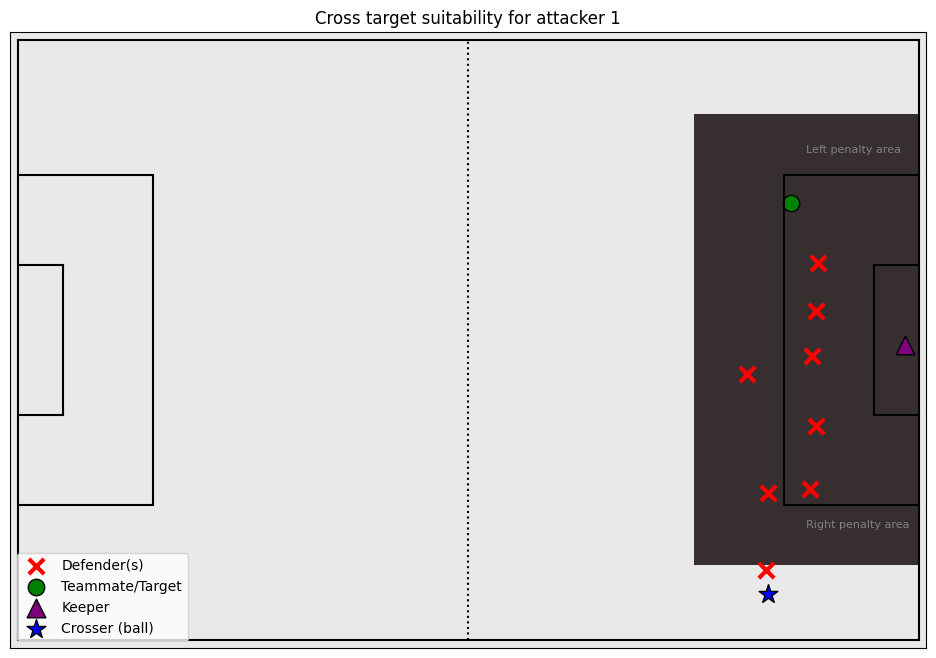

<Figure size 1000x600 with 0 Axes>

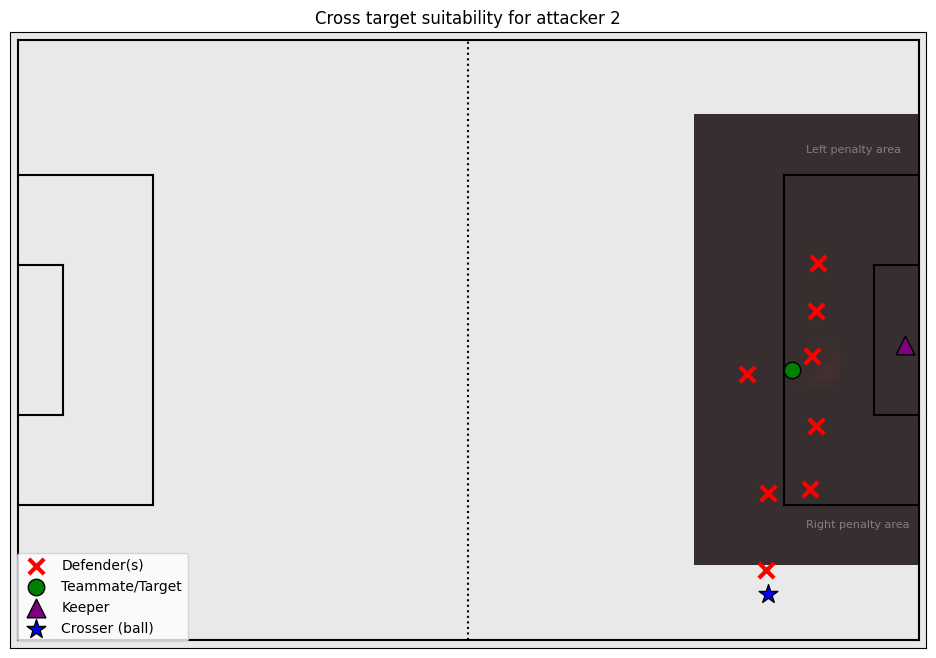

<Figure size 1000x600 with 0 Axes>

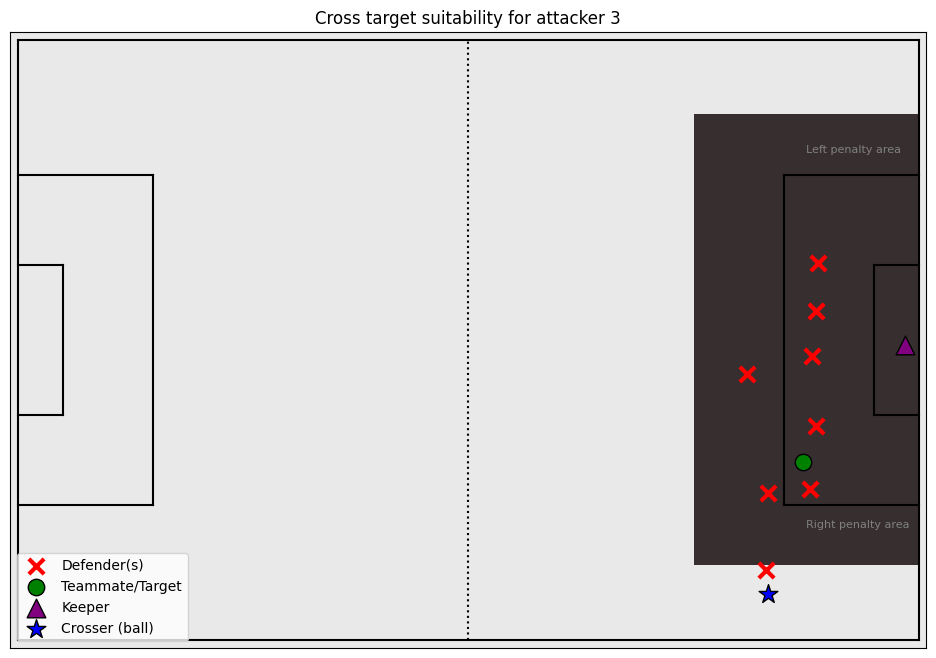

<Figure size 1000x600 with 0 Axes>

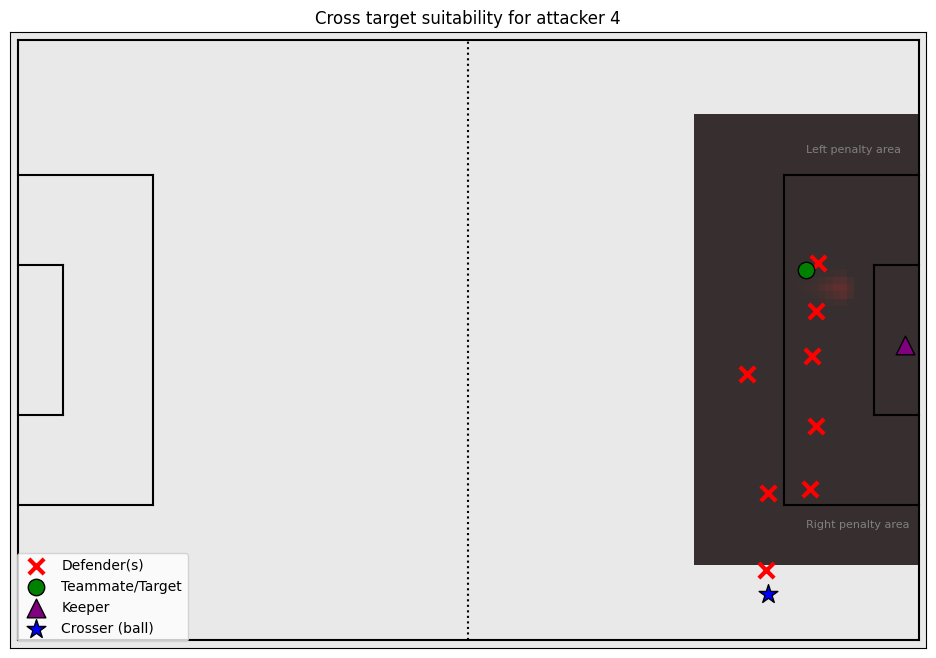

<Figure size 1000x600 with 0 Axes>

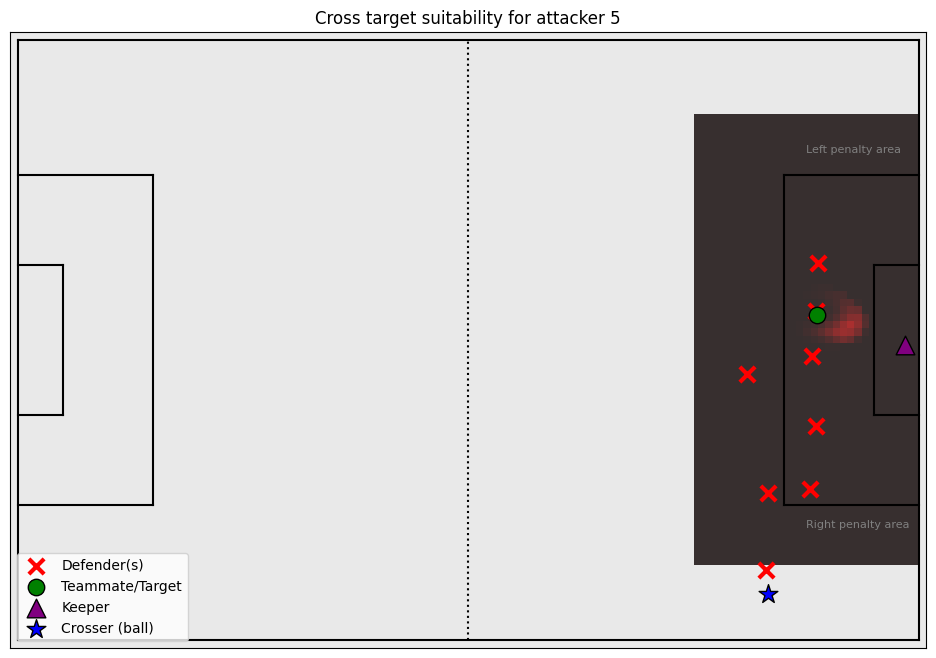

<Figure size 1300x900 with 0 Axes>

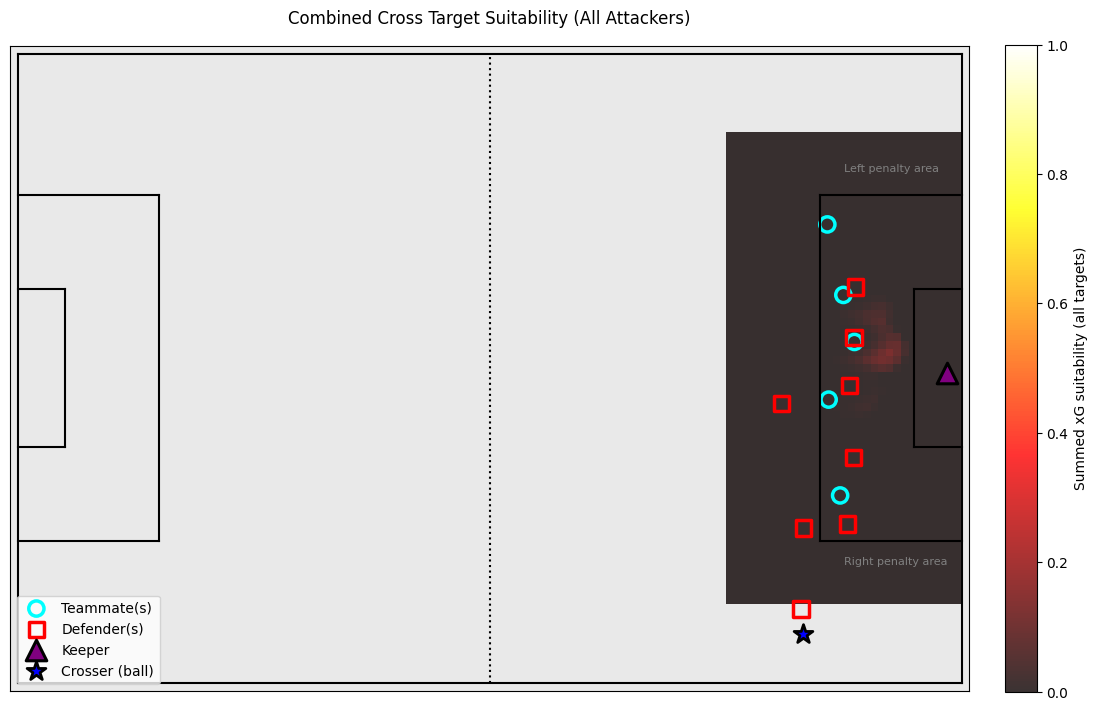

In [40]:
#V2 - combined heatmap

# plotting cross effectiveness heatmap - combined version
import ast
import numpy as np
import matplotlib.pyplot as plt

# === Create xg_from_xy using your existing grid accessors ===
def xg_from_xy(x, y):
    """Return xG value at (x, y) from xg_grid_faded."""
    global xg_grid_faded
    return get_heatmap_value(x, y, grid=xg_grid_faded)


def draw_pitch(ax=None, pitch_color="#e9e9e9", line_color="black", annotate_boxes=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
        ax.set_facecolor(pitch_color)
    ax.plot([0, 0], [0, 80], color=line_color)
    ax.plot([0, 120], [80, 80], color=line_color)
    ax.plot([120, 120], [80, 0], color=line_color)
    ax.plot([120, 0], [0, 0], color=line_color)
    ax.plot([60, 60], [0, 80], color=line_color, linestyle=':')
    ax.plot([18, 18], [18, 62], color=line_color)
    ax.plot([0, 18], [62, 62], color=line_color)
    ax.plot([18, 0], [18, 18], color=line_color)
    ax.plot([102, 102], [18, 62], color=line_color)
    ax.plot([102, 120], [62, 62], color=line_color)
    ax.plot([120, 102], [18, 18], color=line_color)
    ax.plot([0, 6], [30, 30], color=line_color)
    ax.plot([6, 6], [30, 50], color=line_color)
    ax.plot([6, 0], [50, 50], color=line_color)
    ax.plot([120, 114], [30, 30], color=line_color)
    ax.plot([114, 114], [30, 50], color=line_color)
    ax.plot([114, 120], [50, 50], color=line_color)
    ax.set_xlim(-1, 121)
    ax.set_ylim(-1, 81)
    ax.set_xticks([])
    ax.set_yticks([])
    if annotate_boxes:
        ax.text(105, 65, "Left penalty area", fontsize=8, color="gray")
        ax.text(105, 15, "Right penalty area", fontsize=8, color="gray")
    ax.set_aspect('equal')
    return ax


def ellipse_prob(cx, cy, a, b, theta, xx, yy):
    dx = xx - cx
    dy = yy - cy
    xr = np.cos(-theta)*dx - np.sin(-theta)*dy
    yr = np.sin(-theta)*dx + np.cos(-theta)*dy
    val = (xr/a)**2 + (yr/b)**2
    return np.clip(1 - val, 0, 1)


def compute_cross_target_heatmap(
    xg_from_xy, attacker_loc, ball_loc,
    defenders_locs, keeper_loc,
    dx_sum, dt_sum, net_vx_m_s, mean_abs_vx_m_s,
    grid_resolution=1.0, target_bounds=(90,120,10,70)
):
    xmin, xmax, ymin, ymax = target_bounds
    xg = np.arange(xmin, xmax+grid_resolution, grid_resolution)
    yg = np.arange(ymin, ymax+grid_resolution, grid_resolution)
    xx, yy = np.meshgrid(xg, yg)

    # --- attacker reachability ---
    run_time = np.clip(dt_sum, 1.0, 1.8)
    run_speed = max(net_vx_m_s, 4.0)
    a = np.clip(run_speed*run_time, 5.0, 22.0)
    b = 0.6 * a
    theta = np.arctan2(40 - attacker_loc[1], 120 - attacker_loc[0])
    prob_att = ellipse_prob(attacker_loc[0], attacker_loc[1], a, b, theta, xx, yy)

    # --- defenders ---
    prob_def = np.zeros_like(xx)
    for dloc in defenders_locs:
        a_d, b_d = 6.0, 3.0
        p = ellipse_prob(dloc[0], dloc[1], a_d, b_d, 0, xx, yy)
        prob_def = np.maximum(prob_def, p)
    if keeper_loc is not None:
        pk = ellipse_prob(keeper_loc[0], keeper_loc[1], 5.0, 4.0, 0, xx, yy)
        prob_def = np.maximum(prob_def, 1.3 * pk)

    # --- xG surface ---
    xg_map = np.vectorize(xg_from_xy)(xx, yy)

    # --- combine ---
    score = xg_map * prob_att * (1 - np.clip(prob_def, 0, 1))

    # === 1. corridor emphasis between defenders and keeper ===
    if len(defenders_locs) > 0 and keeper_loc is not None:
        x_def_line = np.mean([d[0] for d in defenders_locs])
        x_keeper = keeper_loc[0]
        x_mid = (x_def_line + x_keeper) / 2
        sigma = max(2.0, abs(x_keeper - x_def_line) / 2)
        corridor_boost = np.exp(-0.5 * ((xx - x_mid)/sigma)**2)
        score *= (1.0 + 0.5 * corridor_boost)

    # === 2. defender crowding penalty ===
    if len(defenders_locs) > 0:
        dists = [np.linalg.norm(np.array(attacker_loc) - np.array(d)) for d in defenders_locs]
        nearby = [d for d in dists if d < 10]
        n_close = len(nearby)
        crowding_penalty = 0.8 ** n_close
        score *= crowding_penalty

    # === 3. strong distance-from-goal penalty (element-wise) ===
    goal_x, goal_y = 120, 40
    dist_from_goal = np.sqrt((xx - goal_x)**2 + (yy - goal_y)**2)
    pos_penalty = 1 / (1 + np.exp((dist_from_goal - 12) / 2))
    score *= pos_penalty**1.25

    return score, xx, yy


# --- Extract locations ---
defenders_locations = [
    list(ast.literal_eval(loc)) if isinstance(loc, str) else list(loc)
    for loc in this_three_sixty[(this_three_sixty['teammate'] == 0) & (this_three_sixty['keeper'] == 0)]['location']
]

teammates_locations = [
    list(ast.literal_eval(loc)) if isinstance(loc, str) else list(loc)
    for loc in this_three_sixty[
        (this_three_sixty['teammate'] == 1) & (this_three_sixty['actor'] == 0)
    ]['location']
]

keeper_location = [
    list(ast.literal_eval(loc)) if isinstance(loc, str) else list(loc)
    for loc in this_three_sixty[
        (this_three_sixty['teammate'] == 0) & (this_three_sixty['keeper'] == 1)
    ]['location']
][0]

# Clean input locations
if hasattr(player_location, "iloc"):
    player_location = player_location.iloc[0]
if hasattr(start_location, "iloc"):
    start_location = start_location.iloc[0]

# --- PER-ATTACKER PLOTS + ACCUMULATION ---
heats = []
xx_ref = yy_ref = None

for i, attacker in enumerate(teammates_locations):
    heat, xx, yy = compute_cross_target_heatmap(
        xg_from_xy,
        attacker,             # target teammate
        player_location,      # crosser (ball)
        defenders_locations,
        keeper_location,
        dx_sum, dt_sum,
        net_vx_m_s,
        mean_abs_vx_m_s
    )
    heats.append(np.nan_to_num(heat, nan=0.0))
    if xx_ref is None:
        xx_ref, yy_ref = xx, yy  # remember grid once

    # ---- keep your individual plots (unchanged) ----
    plt.figure()
    draw_pitch()
    vmin_global, vmax_global = 0, 0.6
    plt.imshow(
        heat,
        extent=[90,120,10,70],
        origin='lower',
        cmap='hot',
        alpha=0.8,
        vmin=vmin_global,
        vmax=vmax_global
    )
    plt.title(f"Cross target suitability for attacker {i+1}")

    # overlays
    defenders_x = [d[0] for d in defenders_locations]
    defenders_y = [d[1] for d in defenders_locations]
    plt.scatter(defenders_x, defenders_y, marker='x', c='red', s=120, linewidths=3, label='Defender(s)')
    plt.scatter(attacker[0], attacker[1], marker='o', c='green', s=140, edgecolor='k', label='Teammate/Target')
    if keeper_location is not None:
        plt.scatter(keeper_location[0], keeper_location[1], marker='^', c='purple', s=180, edgecolor='k', label='Keeper')
    if player_location is not None:
        plt.scatter(player_location[0], player_location[1], marker='*', c='blue', s=200, edgecolor='k', label='Crosser (ball)')

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys(), loc='lower left')

# --- COMBINED (SUMMED) HEATMAP ---
if heats:
    combined_heat = np.sum(heats, axis=0)

    plt.figure(figsize=(13, 9))
    ax = draw_pitch()

    # ✅ Keep identical color scheme and scaling as individual maps
    vmin_global, vmax_global = 0, 1#0.3 * len(heats)

    im = plt.imshow(
        combined_heat,
        extent=[90,120,10,70],
        origin='lower',
        cmap='hot',      # same as individual maps
        alpha=0.8,
        vmin=vmin_global,
        vmax=vmax_global
    )
    plt.colorbar(im, ax=ax, label="Summed xG suitability (all targets)", shrink=0.84, pad=0.03)

    # overlays: ALL teammates, defenders, keeper, crosser
    if len(teammates_locations) > 0:
        tx = [float(loc[0]) for loc in teammates_locations]
        ty = [float(loc[1]) for loc in teammates_locations]
        plt.scatter(tx, ty, facecolors='none', edgecolor='cyan', linewidths=2.5, s=120, marker='o', label='Teammate(s)')
    if len(defenders_locations) > 0:
        dxs = [float(loc[0]) for loc in defenders_locations]
        dys = [float(loc[1]) for loc in defenders_locations]
        plt.scatter(dxs, dys, facecolors='none', edgecolor='red', linewidths=2.5, s=120, marker='s', label='Defender(s)')
    if keeper_location is not None:
        plt.scatter([float(keeper_location[0])], [float(keeper_location[1])],
                    c='purple', edgecolor='black', s=220, marker='^', linewidths=2.2, label="Keeper")
    if player_location is not None:
        plt.scatter([float(player_location[0])], [float(player_location[1])],
                    c='blue', edgecolor='black', s=200, marker='*', linewidths=2.0, label="Crosser (ball)")

    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys(), loc='lower left')

    plt.title("Combined Cross Target Suitability (All Attackers)", pad=16)
    plt.tight_layout()
    plt.show()


In [ ]:
#next steps:

    #DONE - finalize the plot that gives a value of xG for each of these squares - the xg from xy thing 

    #DONE - SAVE THE IMAGE 

    #DONE - FIX THE IMAGE - fix the edges, give a more gradual fade out, away from the hot zone (the goal)

    #DONE - try to tweak THE above to make those changes 
        #emphasize the "corridor of uncertainty"
        #scale it based on # defenders around the teammate 
        #MAKE SURE IT IS NOT MULTIPLYING BY THE XG DURING THE ORIGINAL FUNCTION. IT SHOUDL JSUT BE ABOUT PROBABILITY OF RECEIVING THE BALL IN THAT POSITION


    #DONE - somehow multiply the cross effectiveness score by the xG value if the ball gets there 


    #add the individiual heatmaps together to make a final score 
    # the final score for a square is the sum of all the indidivual teammates' heatmap scores 
        #because you dont care which teammate gets on the end of your cross, only that one of them does


    #add in the finishing location of the cross to the COMBINED plot 



    #evaluate that location in context 



## old notes

In [ ]:
#OLD NOTES _ IGNORE

#classifying goal types 


# How it gets to the place where it then goes INTO the shooter . what's the phase of play? 

    # Counter - direct
        # moving a certain distance up the pitch within a certain amount of time, through 1-3 passes


    # Counter - play 
        # - moving a certain distance up the pitch within a certain amount of time in 4+ passes 
        # look the swish assessment. How did you analyse those events
        # - would there be a carry that goes a specific distance within a specific time? 



    # Open play against the low block

        # - can you see the defenders of the team WITH the ball in the freeze frame of the pass into the assister/shooter? are they all in the opponent's half? 
    
        #OR

        # - can you see 8, 9, 10 people on the non-shot team within their own half?


        #has the possession consisted of a sufficient # of passes and a sufficient # of time? (i.e. at least 10 passes, at least 10+ seconds)
            #AND, prior to going into the shooter, the ball is INSIDE the opppsong half third 


    #open play against the MID block 
        # mid block 

    
    
    # Chaos 

    # NON INSTANCES - in other words, the ball started in this area
    #     high turnover , or it's a set piece 



# How it got into the shooter - i.e. how did the space get created for them to shoot 
    #air or ground through ball / grorund pass 
        #look at the pass_through_ball 
    #Cross
        #look at the pass_cross
    #Cut back 
        #look at the pass_cut_back 
    #Chaos
    #long shot 
        #type is a shot, distance from the goal is at least 22 yards (do a pythagorean calculation )
    #high turnover  
        #ball recovery or interception or duel --> ball rec / interception, at a specific X 


#how it went Into the goal
    #chaos
        #Deflection off of either team 
            #shot --> blocks, pass --> blocks and/or ball recoveries in a small space inside the box?
    #Header
    #Volley
    #Shot




# CLASSIFICATION MODIFICATIONS 


# NEW CATEGORIES: how the ball gets into the shooter

    # as in dribbling into the box is a goal type for how it gets into the shooting position 

        #how to spot:
            #the sequence of events is 
                #ball receipt by the person taking the shot 
                #person takes shot 

                #OR

                #Ball receipt 
                #carry
                #shot

                #all by the same person

 

#set back/knockdown – similar to the cutback, that's another type of way that the ball gets to a person who shoots it 

    # Like a player plays it backwards or sideways another player and they shoot it. 









